<center><h1>Verma_Karan_HW4</h1></center>

**Name:** Karan Verma  
**GitHub Username:** *kv304*  
**USC ID:** *5639810577*

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

The imports used throughout the notebook are collected here.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB

import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationError

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 552

The AReM data contain seven activity classes. Each file represents one activity instance with six sensor measurements. I use the extracted `AReM` folder from the homework data directory.

In [2]:
data_dir = Path("hw3_4_data")
zip_file = data_dir / "AReM.zip"
arem_dir = data_dir / "AReM"

if not arem_dir.exists():
    with ZipFile(zip_file, "r") as archive:
        archive.extractall(data_dir)

print("AReM folder:", arem_dir.resolve())
print("Folder exists:", arem_dir.exists())

AReM folder: /Users/karanverma/Documents/USC_classes/DSCI552/hw4/hw3_4_data/AReM
Folder exists: True


In [3]:
sensor_cols = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]

all_cols = ["time"] + sensor_cols
def load_sensor_file(file_path):
    rows = []

    with open(file_path, "r", encoding="utf-8-sig") as file:
        for line in file:
            cleaned_line = line.strip().rstrip(",")

            # Skip headers and empty lines.
            if not cleaned_line or cleaned_line.startswith("#"):
                continue

            # The split also handles the one space-delimited file.
            values = re.split(r"[,\s]+", cleaned_line)

            if len(values) != 7:
                raise ValueError(
                    f"Unexpected row in {file_path.name}: {cleaned_line}"
                )

            rows.append([float(value) for value in values])

    return pd.DataFrame(rows, columns=all_cols)


### (b) Train/Test Split

I follow the split in the assignment. Datasets 1 and 2 from `bending1` and `bending2` are test observations. Datasets 1--3 from the other activities are also test observations. This gives 69 training instances and 19 test instances.

In [4]:
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking",
]


def parse_dataset_id(file_path):
    match = re.search(r"dataset(\d+)", file_path.stem)
    return int(match.group(1))


records = []

for activity in activities:
    activity_folder = arem_dir / activity

    files = sorted(
        activity_folder.glob("dataset*.csv"),
        key=parse_dataset_id,
    )

    for file_path in files:
        dataset_number = parse_dataset_id(file_path)

        if activity in ["bending1", "bending2"]:
            is_test = dataset_number in [1, 2]
        else:
            is_test = dataset_number in [1, 2, 3]

        sensor_data = load_sensor_file(file_path)

        records.append(
            {
                "activity": activity,
                "dataset": dataset_number,
                "split": "test" if is_test else "train",
                "observations": len(sensor_data),
                "file_path": file_path,
            }
        )

manifest = pd.DataFrame(records)

In [5]:
manifest.head()

,activity,dataset,split,observations,file_path
0,bending1,1,test,480,hw3_4_data/AReM/bending1/dataset1.csv
1,bending1,2,test,480,hw3_4_data/AReM/bending1/dataset2.csv
2,bending1,3,train,480,hw3_4_data/AReM/bending1/dataset3.csv
3,bending1,4,train,480,hw3_4_data/AReM/bending1/dataset4.csv
4,bending1,5,train,480,hw3_4_data/AReM/bending1/dataset5.csv


In [6]:
split_counts = (
    manifest
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
)

display(split_counts)

print("Total instances:", len(manifest))
print("Training instances:", (manifest["split"] == "train").sum())
print("Test instances:", (manifest["split"] == "test").sum())

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Total instances: 88
Training instances: 69
Test instances: 19


In [7]:
row_counts = manifest["observations"].value_counts().sort_index()

row_counts

observations
479     1
480    87
Name: count, dtype: int64

In [8]:

manifest.loc[
    manifest["observations"] != 480,
    ["activity", "dataset", "observations"]
]


,activity,dataset,observations
50,sitting,8,479


### (c) Feature Extraction


#### i. Research

Time-domain features summarize a signal using its observed values. Common choices include minimum, maximum, mean, median, standard deviation, quartiles, range, and interquartile range. I calculate the seven statistics requested in the assignment.

#### ii. Extraction

There are seven statistics for each of the six time series, so each instance has $7 \times 6=42$ features.

In [9]:
def extract_features(sensor_data):
    feature_values = {}

    for series_number, signal in enumerate(sensor_cols, start=1):
        measurements = sensor_data[signal]

        feature_values[f"min{series_number}"] = measurements.min()
        feature_values[f"max{series_number}"] = measurements.max()
        feature_values[f"mean{series_number}"] = measurements.mean()
        feature_values[f"median{series_number}"] = measurements.median()
        feature_values[f"std{series_number}"] = measurements.std(ddof=1)
        feature_values[f"q1_{series_number}"] = measurements.quantile(0.25)
        feature_values[f"q3_{series_number}"] = measurements.quantile(0.75)

    return feature_values

In [10]:
feature_records = []

for instance in manifest.itertuples(index=False):
    sensor_data = load_sensor_file(instance.file_path)
    extracted_features = extract_features(sensor_data)

    feature_records.append(
        {
            "activity": instance.activity,
            "dataset": instance.dataset,
            "split": instance.split,
            **extracted_features,
        }
    )

features = pd.DataFrame(feature_records)

display(features.head())
print("Feature table shape:", features.shape)

,activity,dataset,split,min1,max1,mean1,median1,std1,q1_1,q3_1,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Feature table shape: (88, 45)


In [11]:
train_df = features[
    features["split"] == "train"
].reset_index(drop=True)

test_df = features[
    features["split"] == "test"
].reset_index(drop=True)

print("Training feature table:", train_df.shape)
print("Test feature table:", test_df.shape)


Training feature table: (69, 45)
Test feature table: (19, 45)


In [12]:
id_cols = ["activity", "dataset", "split"]

feature_cols = [
    column
    for column in features.columns
    if column not in id_cols
]

print("Number of extracted features:", len(feature_cols))
print(
    "Number of missing feature values:",
    features[feature_cols].isna().sum().sum()
)

assert len(feature_cols) == 42
assert features[feature_cols].isna().sum().sum() == 0


Number of extracted features: 42
Number of missing feature values: 0


In [13]:
display(
    features
    .sort_values(["activity", "dataset"])
    .reset_index(drop=True)
)


,activity,dataset,split,min1,max1,mean1,median1,std1,q1_1,q3_1,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
0,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking,11,train,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,walking,12,train,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,walking,13,train,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,walking,14,train,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


#### iii. Standard Deviation

I compute the sample standard deviation of each feature across the 88 instances. For the 90% bootstrap intervals, I resample the instances 10,000 times and use the 5th and 95th percentiles of the bootstrap standard deviations.

In [14]:
X_features = features[feature_cols].to_numpy()

observed_sd = X_features.std(axis=0, ddof=1)

sd_summary = pd.Series(
    observed_sd,
    index=feature_cols,
    name="Estimated SD",
)

sd_summary.to_frame().round(4)

,Estimated SD
min1,9.5700
max1,4.3944
mean1,5.3357
median1,5.4401
std1,1.7722
q1_1,6.1536
q3_1,5.1389
min2,0.0000
max2,5.0627
mean2,1.5742


In [15]:
rng = np.random.default_rng(552)

n_boot = 10000
n_instances = len(X_features)
n_features = len(feature_cols)

boot_sd = np.empty(
    (n_boot, n_features)
)

for b in range(n_boot):
    row_idx = rng.integers(
        low=0,
        high=n_instances,
        size=n_instances,
    )

    boot_sample = X_features[row_idx]

    boot_sd[b] = boot_sample.std(
        axis=0,
        ddof=1,
    )

In [16]:
ci_low = np.percentile(
    boot_sd,
    5,
    axis=0,
)

ci_high = np.percentile(
    boot_sd,
    95,
    axis=0,
)

bootstrap_summary = pd.DataFrame(
    {
        "Estimated SD": observed_sd,
        "90% CI Lower": ci_low,
        "90% CI Upper": ci_high,
    },
    index=feature_cols,
)

bootstrap_summary.index.name = "Feature"

display(bootstrap_summary.T.round(4))

Feature,min1,max1,mean1,median1,std1,q1_1,q3_1,min2,max2,mean2,...,std5,q1_5,q3_5,min6,max6,mean6,median6,std6,q1_6,q3_6
Estimated SD,9.5700,4.3944,5.3357,5.4401,1.7722,6.1536,5.1389,0.0,5.0627,1.5742,...,1.0249,6.0965,5.5317,0.0458,2.5189,1.1548,1.0865,0.5176,0.7586,1.5236
90% CI Lower,8.2622,3.3280,4.7040,4.7903,1.5722,5.5816,4.3319,0.0,4.6228,1.3941,...,0.8132,4.7701,4.3398,0.0000,2.2508,1.0601,0.9925,0.4781,0.6882,1.3985
90% CI Upper,10.7614,5.2849,5.8864,6.0043,1.9500,6.6524,5.8409,0.0,5.4022,1.7068,...,1.2158,7.2176,6.5283,0.0785,2.7639,1.2163,1.1487,0.5455,0.8087,1.6015


In [17]:
bootstrap_summary["CI Width"] = (
    bootstrap_summary["90% CI Upper"]
    - bootstrap_summary["90% CI Lower"]
)

display(
    bootstrap_summary
    .sort_values("CI Width", ascending=False)
    .round(4)
)

,Estimated SD,90% CI Lower,90% CI Upper,CI Width
Feature,,,,
min5,6.1240,4.4033,7.5110,3.1077
min1,9.5700,8.2622,10.7614,2.4992
q1_5,6.0965,4.7701,7.2176,2.4476
median5,5.8138,4.4902,6.9103,2.4201
mean5,5.6756,4.4016,6.7385,2.3369
q3_5,5.5317,4.3398,6.5283,2.1885
max1,4.3944,3.3280,5.2849,1.9569
max5,5.7412,4.7406,6.5541,1.8134
q3_1,5.1389,4.3319,5.8409,1.5089


#### iv. Select Features

I select **minimum, mean, and maximum**. The mean describes the overall signal level, while the minimum and maximum describe its observed range. These three features are simple to interpret and provide a reasonable summary for the classification plots.

In [18]:
summary = pd.Series({
    "Total instances": len(manifest),
    "Training instances": len(train_df),
    "Test instances": len(test_df),
    "Extracted features": len(feature_cols),
    "Missing feature values": int(features[feature_cols].isna().sum().sum()),
})
summary.to_frame("Value")

,Value
Total instances,88
Training instances,69
Test instances,19
Extracted features,42
Missing feature values,0


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

I use the 69 training instances for model selection. The 19 test instances remain held out until the final evaluations.

The following functions create the segmented feature tables used in Question 2.

In [19]:
def binary_label_from_activity(activity):
    return int("bending" in activity.lower())


def split_signal_into_l_parts(signal, l):
    """Split one signal into l approximately equal pieces."""
    return np.array_split(np.asarray(signal), l)


def get_segment_features(sensor_data, l):
    """Compute the seven time-domain features for every sensor segment."""
    values = {}

    for series_number, signal_name in enumerate(sensor_cols, start=1):
        segments = split_signal_into_l_parts(sensor_data[signal_name], l)
        for segment_number, segment in enumerate(segments, start=1):
            x = pd.Series(segment)
            suffix = f"{series_number}_{segment_number}"
            values[f"min{suffix}"] = x.min()
            values[f"max{suffix}"] = x.max()
            values[f"mean{suffix}"] = x.mean()
            values[f"median{suffix}"] = x.median()
            values[f"std{suffix}"] = x.std(ddof=1)
            values[f"q1{suffix}"] = x.quantile(0.25)
            values[f"q3{suffix}"] = x.quantile(0.75)

    return values


feature_cache = {}


def make_segment_features(manifest_df, l):
    if l in feature_cache:
        return feature_cache[l].copy()

    rows = []
    for instance in manifest_df.itertuples(index=False):
        sensor_data = load_sensor_file(instance.file_path)
        rows.append({
            "activity": instance.activity,
            "dataset": instance.dataset,
            "split": instance.split,
            "binary_y": binary_label_from_activity(instance.activity),
            **get_segment_features(sensor_data, l),
        })

    feature_cache[l] = pd.DataFrame(rows)
    return feature_cache[l].copy()


def get_feature_columns(df, extra_id_cols=None):
    id_cols = ["activity", "dataset", "split"]
    if extra_id_cols:
        id_cols += extra_id_cols
    return [column for column in df.columns if column not in id_cols]


def get_binary_split(df):
    train = df[df["split"] == "train"].reset_index(drop=True)
    test = df[df["split"] == "test"].reset_index(drop=True)
    columns = get_feature_columns(df, extra_id_cols=["binary_y"])
    return (
        train,
        test,
        columns,
        train[columns],
        train["binary_y"],
        test[columns],
        test["binary_y"],
    )

In [20]:
features_l1 = make_segment_features(manifest, l=1)
featurecols_l1 = get_feature_columns(features_l1, extra_id_cols=["binary_y"])

print("Training instances:", (features_l1["split"] == "train").sum())
print("Test instances:", (features_l1["split"] == "test").sum())
print("Features for l=1:", len(featurecols_l1))
print("Missing values:", int(features_l1[featurecols_l1].isna().sum().sum()))

Training instances: 69
Test instances: 19
Features for l=1: 42
Missing values: 0


### 2(a)(i) Binary Scatter Plots

The plots compare minimum, mean, and maximum for time series 1, 2, and 6 in the training set. Bending is the positive class and all other activities form the negative class.

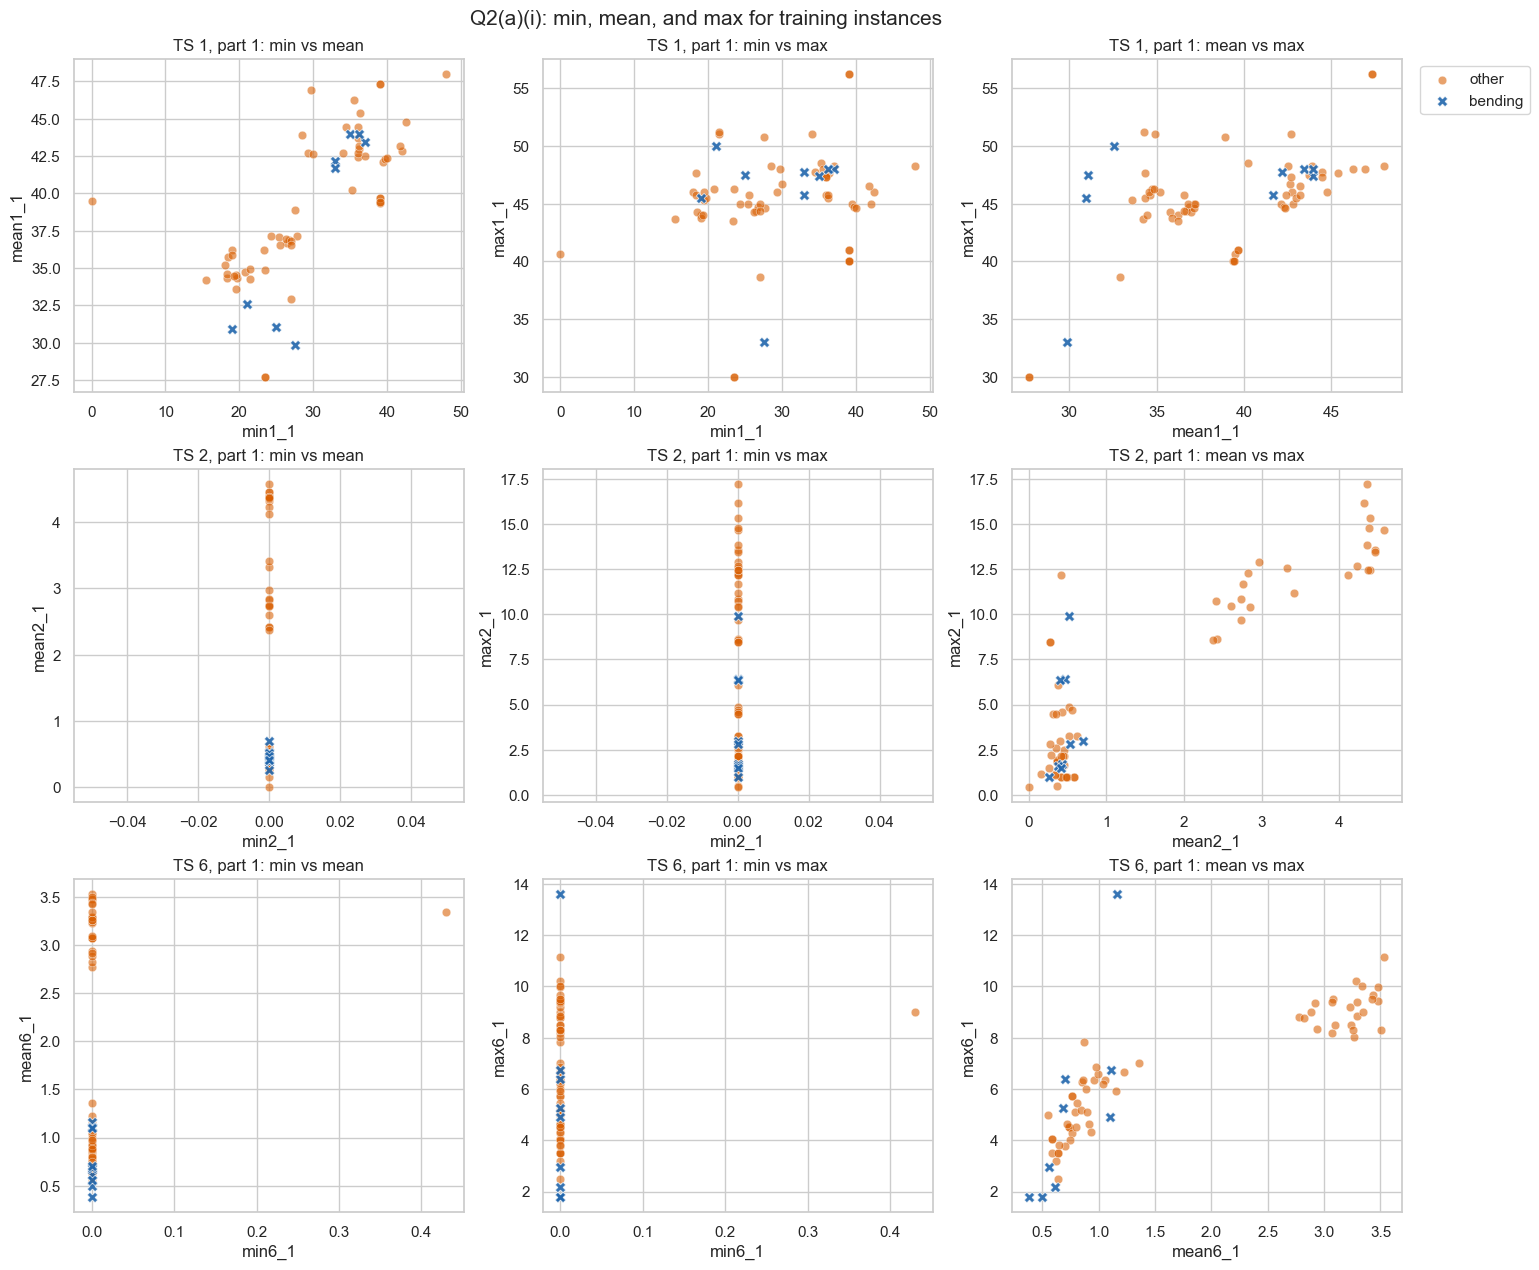

In [21]:

scatter_train = features_l1[features_l1["split"] == "train"].copy()
scatter_train["binary_label"] = scatter_train["binary_y"].map(
    {1: "bending", 0: "other"}
)


def plot_feature_triplets(df, series_segments, title):
    pairs = [("min", "mean"), ("min", "max"), ("mean", "max")]
    palette = {"bending": "#2166ac", "other": "#d95f02"}
    markers = {"bending": "X", "other": "o"}

    fig, axes = plt.subplots(
        len(series_segments), 3,
        figsize=(14, 4.1 * len(series_segments)),
        constrained_layout=True,
    )
    axes = np.atleast_2d(axes)

    for row, (series_number, segment_number) in enumerate(series_segments):
        suffix = f"{series_number}_{segment_number}"
        for col, (x_stat, y_stat) in enumerate(pairs):
            ax = axes[row, col]
            for label in ["other", "bending"]:
                part = df[df["binary_label"] == label]
                ax.scatter(
                    part[f"{x_stat}{suffix}"],
                    part[f"{y_stat}{suffix}"],
                    label=label,
                    color=palette[label],
                    marker=markers[label],
                    s=55 if label == "bending" else 38,
                    alpha=0.9 if label == "bending" else 0.58,
                    edgecolor="white",
                    linewidth=0.45,
                )
            ax.set_xlabel(f"{x_stat}{suffix}")
            ax.set_ylabel(f"{y_stat}{suffix}")
            ax.set_title(
                f"TS {series_number}, part {segment_number}: "
                f"{x_stat} vs {y_stat}"
            )

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(1.005, 0.98), ncol=1, frameon=True)
    fig.suptitle(title, fontsize=15, y=1.02)
    plt.show()


plot_feature_triplets(
    scatter_train,
    [(1, 1), (2, 1), (6, 1)],
    "Q2(a)(i): min, mean, and max for training instances",
)


The full-series plots show useful class differences, although there is still overlap in several views.

### 2(a)(ii) Scatter Plots After Splitting Each Series

I repeat the plots after dividing each time series into two approximately equal segments.

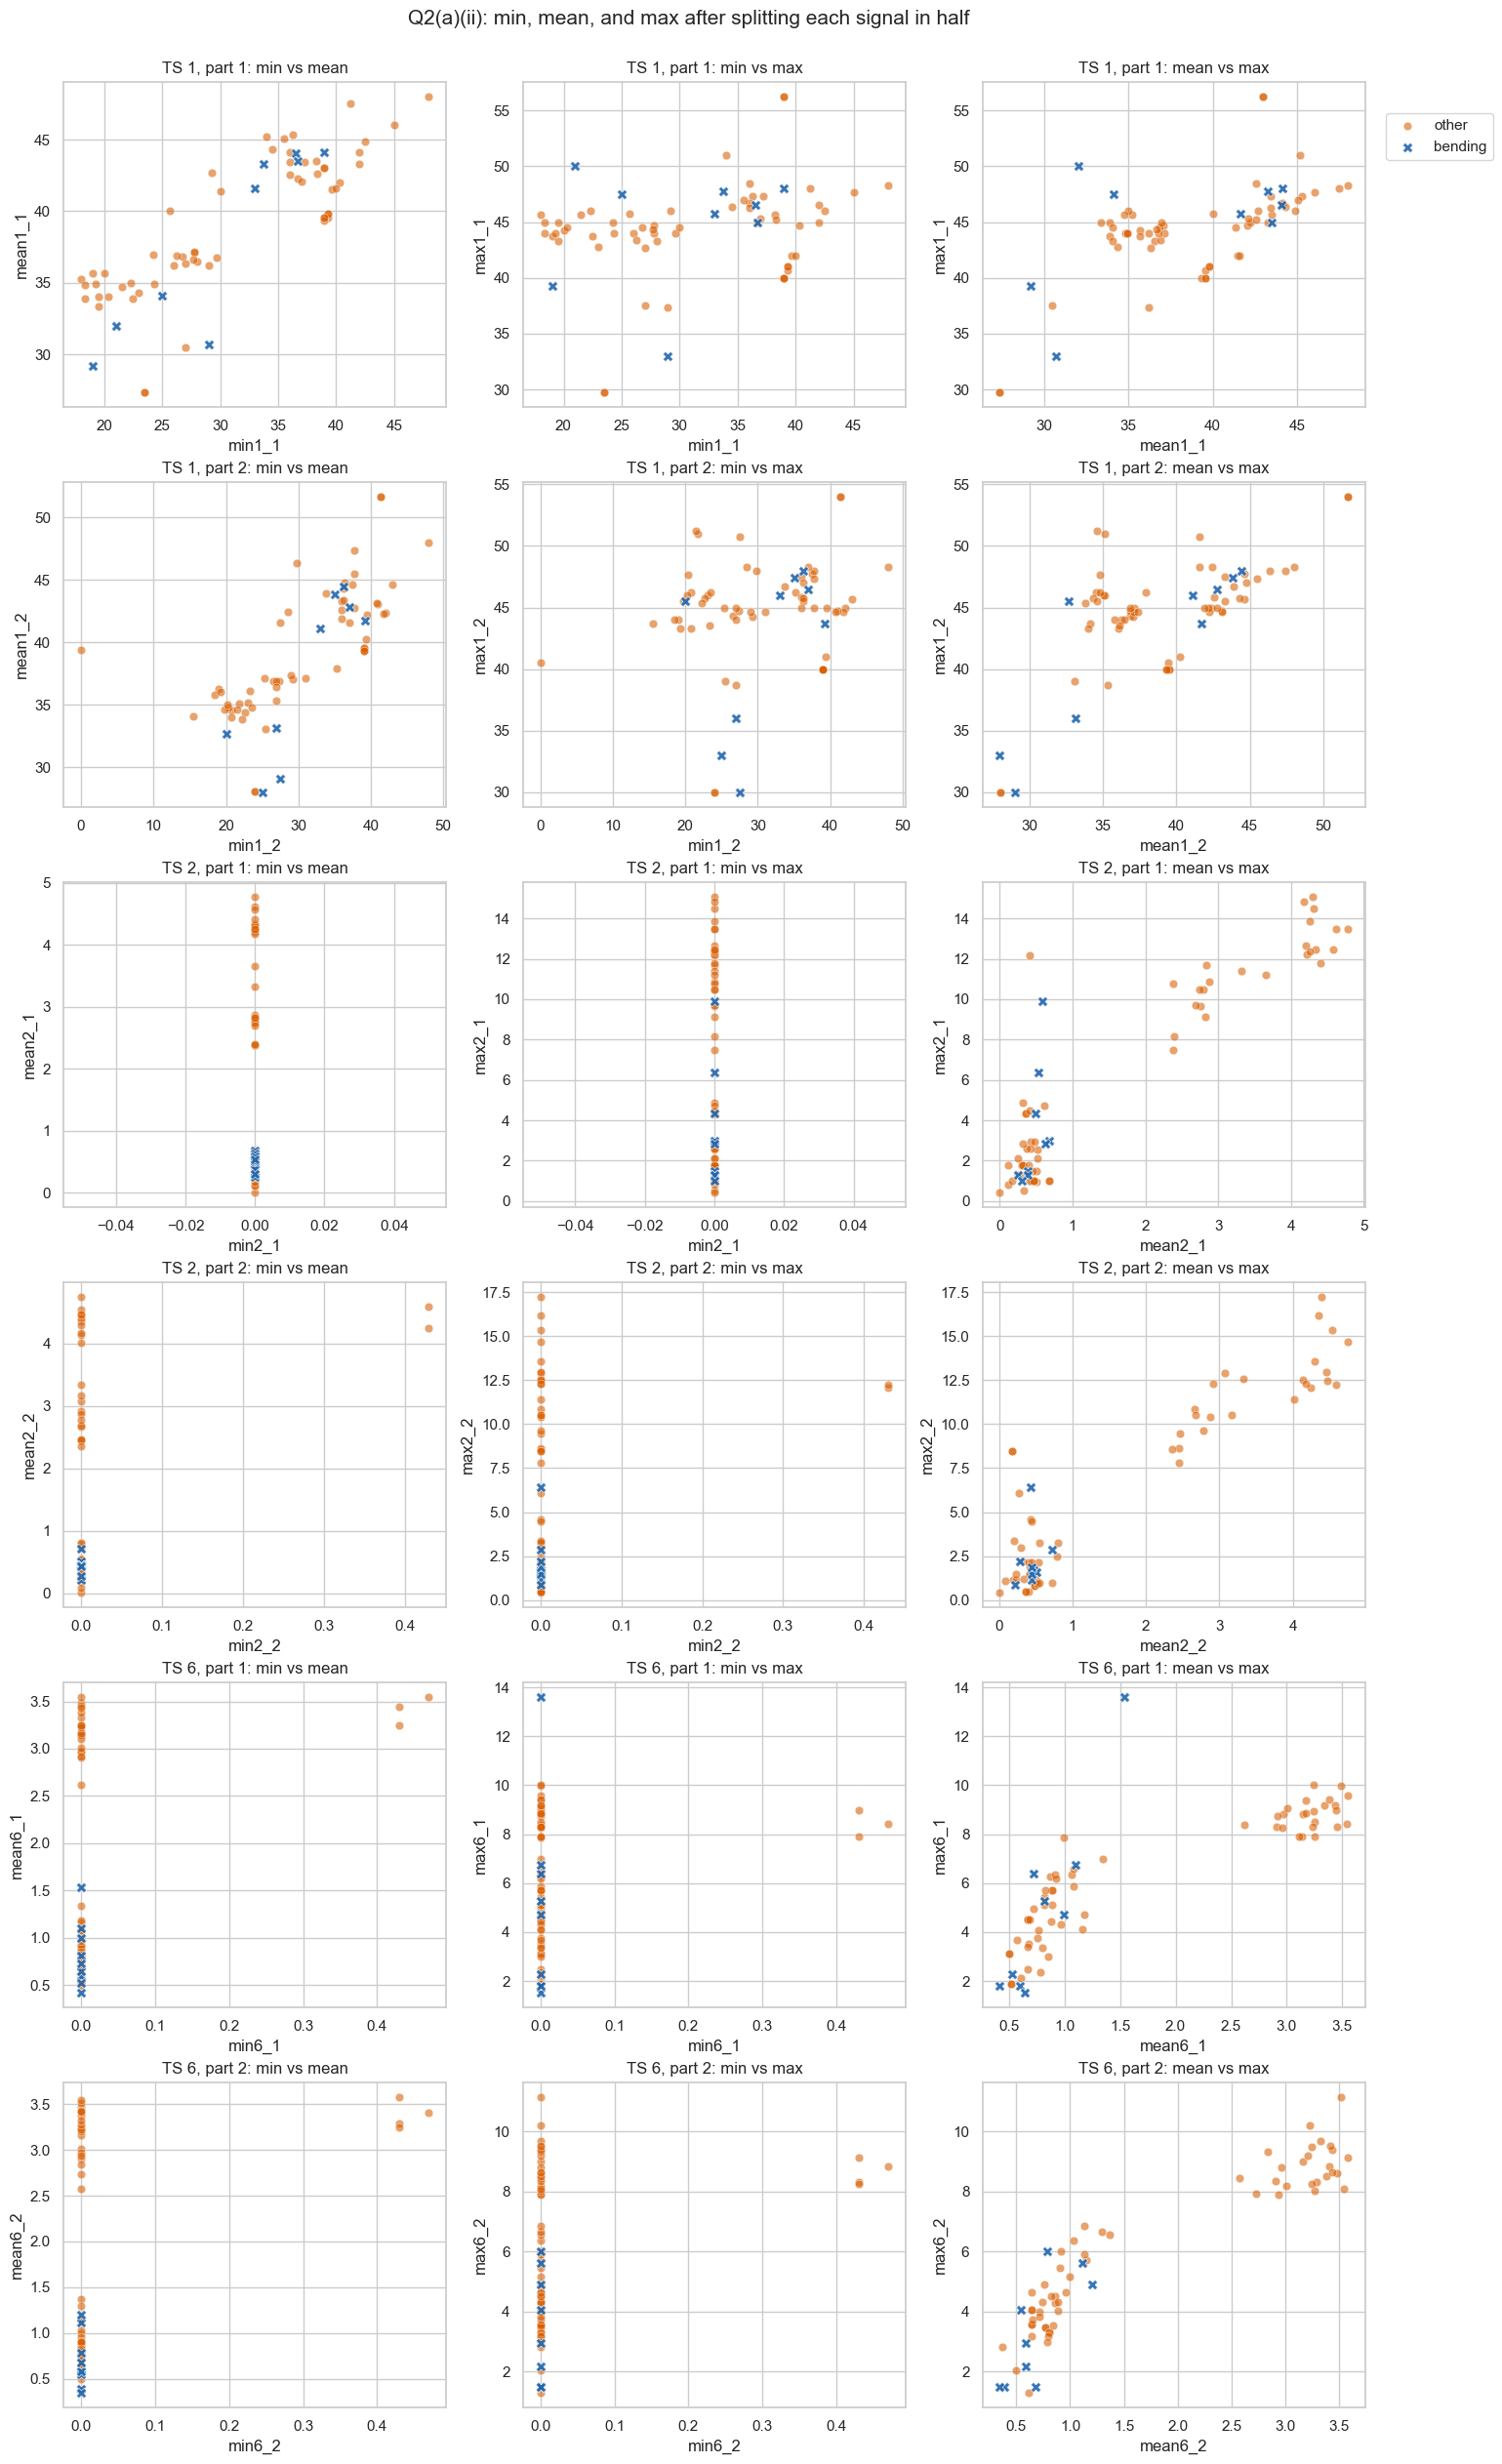

In [22]:


features_l2 = make_segment_features(manifest, l=2)
scatter_train_l2 = features_l2[features_l2["split"] == "train"].copy()
scatter_train_l2["binary_label"] = scatter_train_l2["binary_y"].map(
    {1: "bending", 0: "other"}
)

plot_feature_triplets(
    scatter_train_l2,
    [
        (1, 1), (1, 2),
        (2, 1), (2, 2),
        (6, 1), (6, 2),
    ],
    "Q2(a)(ii): min, mean, and max after splitting each signal in half",
)


Splitting the series adds some useful local information, but it does not make the two classes perfectly separable in every plot.

### 2(a)(iii) Cross-Validation and RFE

I use recursive feature elimination as the allowed backward-selection alternative to p-value-based pruning. Because the unpenalized model exhibits separation, conventional Wald p-values are not reliable for inference.

For each CV split, I fit the scaler and RFE only on that fold's training data. This prevents the validation fold from affecting feature selection. It would be incorrect to select features using all 69 training observations before cross-validation, since the validation folds would influence the chosen features. I use stratified 5-fold CV because the training set contains 9 bending and 60 non-bending observations.

To keep the search manageable, I evaluate a practical grid of retained-feature counts instead of every possible value of $p$.

In [23]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

l_values = list(range(1, 21))
# A prespecified, computationally manageable grid for the number retained.
p_grid = [3, 6, 9, 12, 15, 18, 24, 30, 36, 42]

cv_rows = []

for l in l_values:
    feature_table_l = make_segment_features(manifest, l=l)
    train_l, test_l, featurecols_l, X_train_l, y_train_l, X_test_l, y_test_l = get_binary_split(feature_table_l)
    
    total_features_l = len(featurecols_l)
    valid_p_grid = [p for p in p_grid if p <= total_features_l]
    
    for p in valid_p_grid:
        base_model = LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=3000
        )
        
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(estimator=base_model, n_features_to_select=p)),
            ("logit", LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=3000
            ))
        ])
        
        scores = cross_val_score(pipe, X_train_l, y_train_l, cv=cv, scoring="accuracy", n_jobs=-1)
        
        cv_rows.append({
            "l": l,
            "p": p,
            "mean_cv_accuracy": scores.mean(),
            "std_cv_accuracy": scores.std(),
            "num_features_before_selection": total_features_l
        })

cv_results = pd.DataFrame(cv_rows).sort_values(
    by=["mean_cv_accuracy", "std_cv_accuracy"],
    ascending=[False, True]
).reset_index(drop=True)

cv_results.head(15)


,l,p,mean_cv_accuracy,std_cv_accuracy,num_features_before_selection
0,1,6,0.985714,0.028571,42
1,18,3,0.985714,0.028571,756
2,18,9,0.971429,0.034993,756
3,19,9,0.971429,0.034993,798
4,17,6,0.971429,0.057143,714
5,1,9,0.957143,0.034993,42
6,9,6,0.957143,0.034993,378
7,20,6,0.957143,0.034993,840
8,1,15,0.957143,0.057143,42
9,3,15,0.957143,0.057143,126


In [24]:
# Best (l, p) pair

best_lp = cv_results.iloc[0]
best_l = int(best_lp["l"])
best_p = int(best_lp["p"])

print("Best l:", best_l)
print("Best p:", best_p)
print("Best mean CV accuracy:", round(best_lp["mean_cv_accuracy"], 4))
print("Best CV std:", round(best_lp["std_cv_accuracy"], 4))


Best l: 1
Best p: 6
Best mean CV accuracy: 0.9857
Best CV std: 0.0286


The best pair is $l=1$ and $p=6$, with mean CV accuracy 0.9857. The $l=18$, $p=3$ candidate has the same rounded score, so I keep the simpler $l=1$ representation.

### 2(a)(iv)-(vii) Final Binary Logistic Regression

I refit the scaler, RFE, and unpenalized logistic model using the selected $l$ and $p$ values.

In [25]:

best_feature_table = make_segment_features(manifest, l=best_l)
best_train, best_test, best_featurecols, X_train, y_train, X_test, y_test = get_binary_split(best_feature_table)

# Standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# RFE
base_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=3000
)

rfe = RFE(estimator=base_model, n_features_to_select=best_p, step=1)
X_train_selected = rfe.fit_transform(X_train_scaled, y_train)
X_test_selected = rfe.transform(X_test_scaled)

selected_features = np.array(best_featurecols)[rfe.support_]
selected_features


array(['q31_1', 'max4_1', 'q14_1', 'min5_1', 'max5_1', 'q16_1'],
      dtype='<U9')

In [26]:
final_logit = LogisticRegression(
    penalty=None, solver="lbfgs", max_iter=3000
).fit(X_train_selected, y_train)

X_train_sm = pd.DataFrame(X_train_selected, columns=selected_features)
X_train_sm = sm.add_constant(X_train_sm, has_constant="add")

try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sm_logit = sm.Logit(
            y_train.reset_index(drop=True), X_train_sm
        ).fit(disp=False, maxiter=100)

    fit_converged = bool(sm_logit.mle_retvals.get("converged", False))
    has_separation = not fit_converged or not np.isfinite(sm_logit.pvalues).all()
    coef_table = pd.DataFrame({
        "feature": X_train_sm.columns,
        "coefficient": sm_logit.params.to_numpy(),
        "p_value": sm_logit.pvalues.to_numpy(),
    })
except (np.linalg.LinAlgError, PerfectSeparationError):
    has_separation = True
    coef_table = pd.DataFrame({
        "feature": ["const", *selected_features],
        "coefficient": np.r_[final_logit.intercept_, final_logit.coef_.ravel()],
        "p_value": "Not estimable",
    })

if has_separation:
    coef_table["p_value"] = "Not estimable"
    print(
        "The classes are completely or nearly completely separated, so "
        "ordinary Wald p-values are not estimable."
    )

display(coef_table)

The classes are completely or nearly completely separated, so ordinary Wald p-values are not estimable.


,feature,coefficient,p_value
0,const,-59.094802,Not estimable
1,q31_1,-15.397028,Not estimable
2,max4_1,14.663274,Not estimable
3,q14_1,-8.969894,Not estimable
4,min5_1,36.447562,Not estimable
5,max5_1,24.176488,Not estimable
6,q16_1,-24.142042,Not estimable


The unpenalized logistic model shows complete or near-complete separation. Because of this, the usual maximum-likelihood coefficient estimates and Wald p-values are not stable. I use scikit-learn for classification performance. The statsmodels fit is only used to check coefficient inference and p-values.

#### Training Performance

Binary Logistic Regression - Train confusion matrix:
 [[60  0]
 [ 0  9]]
Binary Logistic Regression - Train accuracy: 1.0


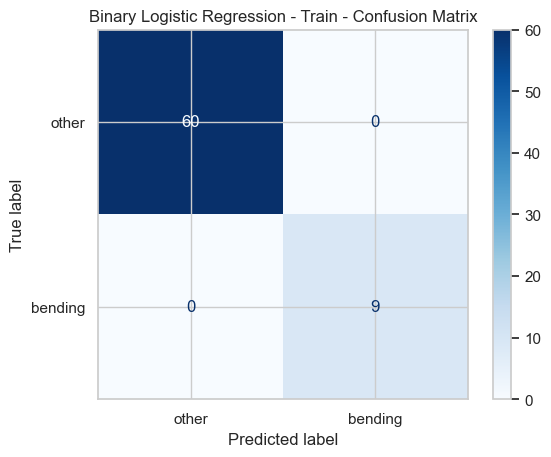

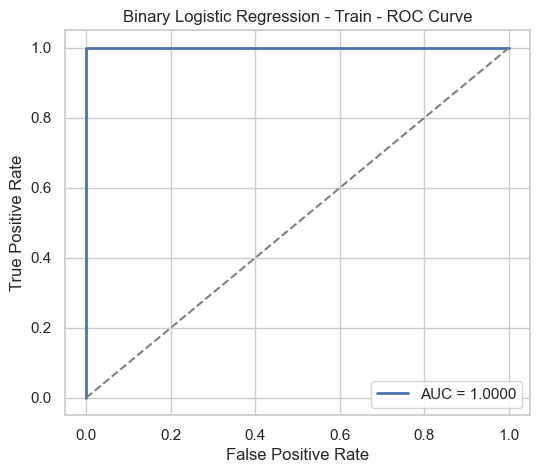

In [27]:


def plot_binary_diagnostics(y_true, probabilities, title, cmap="Blues"):
    predictions = (np.asarray(probabilities) >= 0.5).astype(int)
    cm = confusion_matrix(y_true, predictions)

    print(f"{title} confusion matrix:\n", cm)
    print(f"{title} accuracy:", round(accuracy_score(y_true, predictions), 4))

    ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot(
        cmap=cmap
    )
    plt.title(f"{title} - Confusion Matrix")
    plt.show()

    auc_value = roc_auc_score(y_true, probabilities)
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_value:.4f}")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{title} - ROC Curve")
    plt.legend()
    plt.show()
    return cm, auc_value


train_probs = final_logit.predict_proba(X_train_selected)[:, 1]
cm_train, train_auc = plot_binary_diagnostics(
    y_train, train_probs, "Binary Logistic Regression - Train"
)


The model classifies all 69 training instances correctly and has a training AUC of 1.0000.

#### Test Performance

Binary Logistic Regression - Test confusion matrix:
 [[15  0]
 [ 0  4]]
Binary Logistic Regression - Test accuracy: 1.0


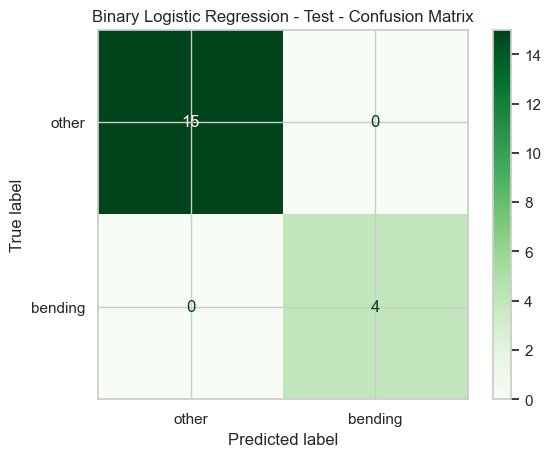

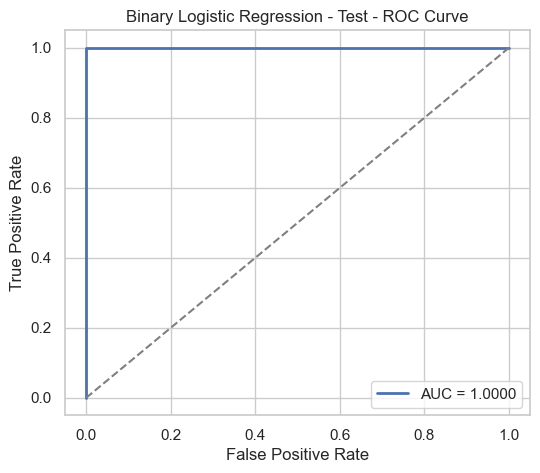

Test accuracy: 1.0
Test AUC: 1.0
Best CV accuracy: 0.9857


In [28]:
test_probs = final_logit.predict_proba(X_test_selected)[:, 1]
cm_test, test_auc = plot_binary_diagnostics(
    y_test, test_probs, "Binary Logistic Regression - Test", cmap="Greens"
)

test_preds = (test_probs >= 0.5).astype(int)
print("Test accuracy:", round(accuracy_score(y_test, test_preds), 4))
print("Test AUC:", round(test_auc, 4))
print("Best CV accuracy:", round(best_lp["mean_cv_accuracy"], 4))


The held-out test accuracy and AUC are both 1.0000. The test set was not used to choose $l$, $p$, or the selected features.

#### Separation Check

In [29]:
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
coef_table.sort_values("abs_coefficient", ascending=False).head(15)


,feature,coefficient,p_value,abs_coefficient
0,const,-59.094802,Not estimable,59.094802
4,min5_1,36.447562,Not estimable,36.447562
5,max5_1,24.176488,Not estimable,24.176488
6,q16_1,-24.142042,Not estimable,24.142042
1,q31_1,-15.397028,Not estimable,15.397028
2,max4_1,14.663274,Not estimable,14.663274
3,q14_1,-8.969894,Not estimable,8.969894


The large coefficients and unavailable Wald p-values are consistent with separation. RFE, rather than the p-values, was used to select the final predictors.

#### Case-Control Sampling and Intercept Adjustment

The training set is imbalanced, with bending as the minority class. I fit a case-control version using all bending cases and an equal number of non-bending cases, then adjust the intercept back to the original class prevalence.

Original bending prevalence: 0.1304
Case-control bending prevalence: 0.5
Intercept correction: -1.8971
Raw intercept: -5.2887
Adjusted intercept: -7.1859
Adjusted Case-Control Model - Train confusion matrix:
 [[59  1]
 [ 0  9]]
Adjusted Case-Control Model - Train accuracy: 0.9855


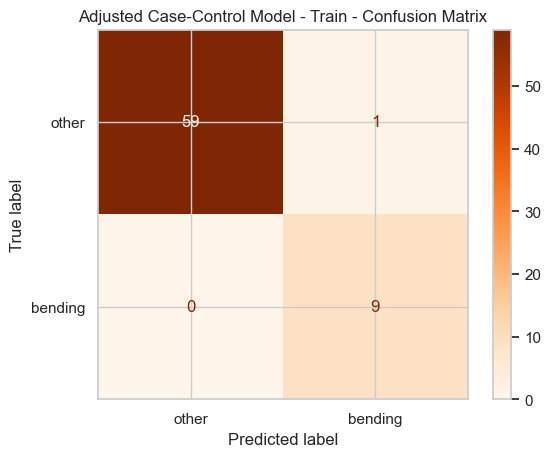

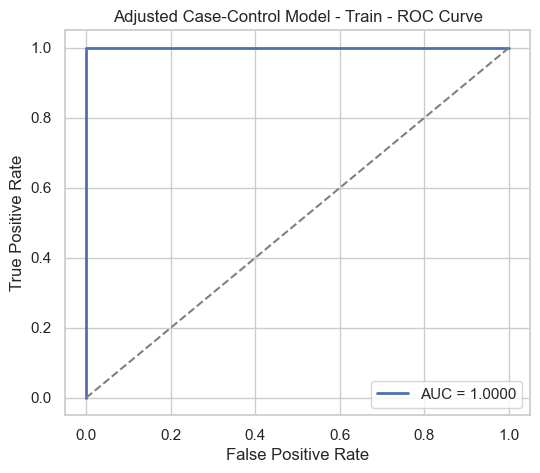

Adjusted Case-Control Model - Test confusion matrix:
 [[15  0]
 [ 0  4]]
Adjusted Case-Control Model - Test accuracy: 1.0


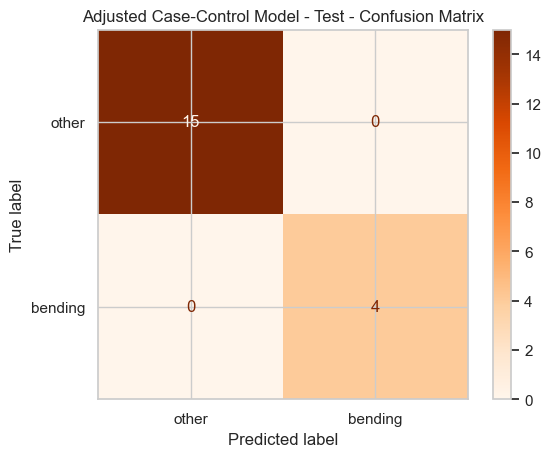

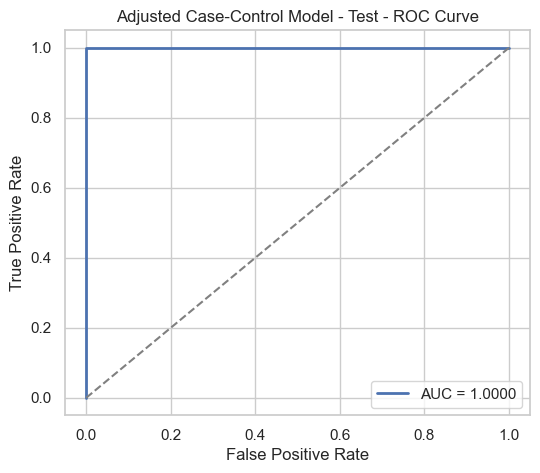

In [30]:
selected_train = pd.DataFrame(X_train_selected, columns=selected_features)
selected_train["binary_y"] = y_train.to_numpy()

cases = selected_train[selected_train["binary_y"] == 1]
controls = selected_train[selected_train["binary_y"] == 0].sample(
    n=len(cases), random_state=RANDOM_STATE
)
case_control_train = pd.concat([cases, controls]).sample(
    frac=1, random_state=RANDOM_STATE
)

X_cc = case_control_train.drop(columns="binary_y")
y_cc = case_control_train["binary_y"]
case_control_model = LogisticRegression(
    penalty=None, solver="lbfgs", max_iter=3000
).fit(X_cc, y_cc)

population_prevalence = y_train.mean()
sample_prevalence = y_cc.mean()
intercept_correction = (
    np.log(population_prevalence / (1 - population_prevalence))
    - np.log(sample_prevalence / (1 - sample_prevalence))
)
adjusted_intercept = case_control_model.intercept_[0] + intercept_correction


def case_control_probs(X):
    scores = np.asarray(X) @ case_control_model.coef_[0] + adjusted_intercept
    return 1 / (1 + np.exp(-scores))


print("Original bending prevalence:", round(population_prevalence, 4))
print("Case-control bending prevalence:", round(sample_prevalence, 4))
print("Intercept correction:", round(intercept_correction, 4))
print("Raw intercept:", round(case_control_model.intercept_[0], 4))
print("Adjusted intercept:", round(adjusted_intercept, 4))

cc_train_probs = case_control_probs(X_train_selected)
cm_cc_train, cc_train_auc = plot_binary_diagnostics(
    y_train, cc_train_probs, "Adjusted Case-Control Model - Train", cmap="Oranges"
)

cc_test_probs = case_control_probs(X_test_selected)
cm_cc_test, cc_test_auc = plot_binary_diagnostics(
    y_test, cc_test_probs, "Adjusted Case-Control Model - Test", cmap="Oranges"
)

The adjusted case-control model makes one training error and no test errors. Its test AUC is 1.0000.

### 2(b) L1-Penalized Binary Logistic Regression

I select both $l$ and the regularization parameter $C$ using the same stratified 5-fold CV structure.

In [31]:


l1_rows = []

for l in range(1, 21):
    feature_table_l = make_segment_features(manifest, l=l)
    train_l, test_l, featurecols_l, X_train_l, y_train_l, X_test_l, y_test_l = get_binary_split(feature_table_l)
    
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])
    
    param_grid = {
        "logit__C": np.logspace(-3, 3, 20)
    }
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X_train_l, y_train_l)
    
    l1_rows.append({
        "l": l,
        "best_C": grid.best_params_["logit__C"],
        "best_cv_accuracy": grid.best_score_
    })

l1_results = pd.DataFrame(l1_rows).sort_values("best_cv_accuracy", ascending=False).reset_index(drop=True)
l1_results.head(10)


,l,best_C,best_cv_accuracy
0,11,1.438450,0.985714
1,12,0.695193,0.985714
2,19,26.366509,0.985714
3,18,6.158482,0.985714
4,13,0.695193,0.971429
5,1,0.335982,0.971429
6,3,0.335982,0.971429
7,20,2.976351,0.971429
8,2,1.438450,0.957143
9,6,233.572147,0.957143


In [32]:
# Best L1 model

best_l1_l = int(l1_results.iloc[0]["l"])
best_l1_C = float(l1_results.iloc[0]["best_C"])

print("Best l for L1 logistic regression:", best_l1_l)
print("Best C for L1 logistic regression:", best_l1_C)
print("Best CV accuracy:", round(l1_results.iloc[0]["best_cv_accuracy"], 4))


Best l for L1 logistic regression: 11
Best C for L1 logistic regression: 1.438449888287663
Best CV accuracy: 0.9857


In [33]:
# Fit final L1 model and inspect nonzero coefficients

best_l1_table = make_segment_features(manifest, l=best_l1_l)
best_l1_train, best_l1_test, best_l1_featurecols, X_train_l1, y_train_l1, X_test_l1, y_test_l1 = get_binary_split(best_l1_table)

l1_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=best_l1_C,
        max_iter=5000,
        random_state=RANDOM_STATE
    ))
])

l1_pipe.fit(X_train_l1, y_train_l1)

l1_coefs = pd.Series(
    l1_pipe.named_steps["logit"].coef_[0],
    index=best_l1_featurecols
)

nonzero_l1 = l1_coefs[l1_coefs != 0].sort_values(key=np.abs, ascending=False)
nonzero_l1.head(20)


q15_2        1.487731
max1_6      -0.919302
min5_10      0.829634
median5_2    0.564384
median4_8   -0.456424
max5_1       0.400568
std6_9      -0.077412
max6_10     -0.045531
dtype: float64

In [34]:
print("Best CV accuracy from unpenalized logistic regression with RFE:", round(best_lp["mean_cv_accuracy"], 4))
print("Best CV accuracy from L1 route:", round(l1_results.iloc[0]["best_cv_accuracy"], 4))


Best CV accuracy from unpenalized logistic regression with RFE: 0.9857
Best CV accuracy from L1 route: 0.9857


Both methods have a best CV accuracy of 0.9857. L1 logistic regression performs feature selection during fitting and remains numerically stable under separation. Unpenalized logistic regression with RFE uses a separate feature-selection step, and its Wald p-values are not reliable here.

### 2(c) Multiclass Classification

#### L1-Penalized Multinomial Logistic Regression

The `bending2` class has only four training instances, so I use four stratified folds for the multiclass models.

In [35]:

multiclass_cv = StratifiedKFold(
    n_splits=4, shuffle=True, random_state=RANDOM_STATE
)
multiclass_rows = []

for l in range(1, 21):
    feature_table_l = make_segment_features(manifest, l=l)
    train_mc = feature_table_l[
        feature_table_l["split"] == "train"
    ].reset_index(drop=True)

    featurecols_mc = [
        c for c in feature_table_l.columns
        if c not in ["activity", "dataset", "split", "binary_y"]
    ]
    X_train_mc = train_mc[featurecols_mc]
    y_train_mc = train_mc["activity"]

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression(
            penalty="l1",
            solver="saga",
            multi_class="multinomial",
            max_iter=10000,
            tol=1e-4,
            random_state=RANDOM_STATE,
        )),
    ])

    grid = GridSearchCV(
        pipe,
        {"logit__C": np.logspace(-3, 2, 12)},
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    grid.fit(X_train_mc, y_train_mc)

    multiclass_rows.append({
        "l": l,
        "best_C": grid.best_params_["logit__C"],
        "best_cv_accuracy": grid.best_score_,
    })

multi_cv_results = pd.DataFrame(multiclass_rows).sort_values(
    ["best_cv_accuracy", "l"], ascending=[False, True]
).reset_index(drop=True)
multi_cv_results.head(10)


,l,best_C,best_cv_accuracy
0,2,4.328761,0.914216
1,1,1.519911,0.900327
2,3,35.111917,0.883170
3,4,100.000000,0.883170
4,5,35.111917,0.868464
5,18,100.000000,0.868464
6,19,100.000000,0.854575
7,9,4.328761,0.840686
8,20,12.328467,0.840686
9,15,4.328761,0.840686


Multiclass test accuracy: 0.8421
Multiclass test error: 0.1579


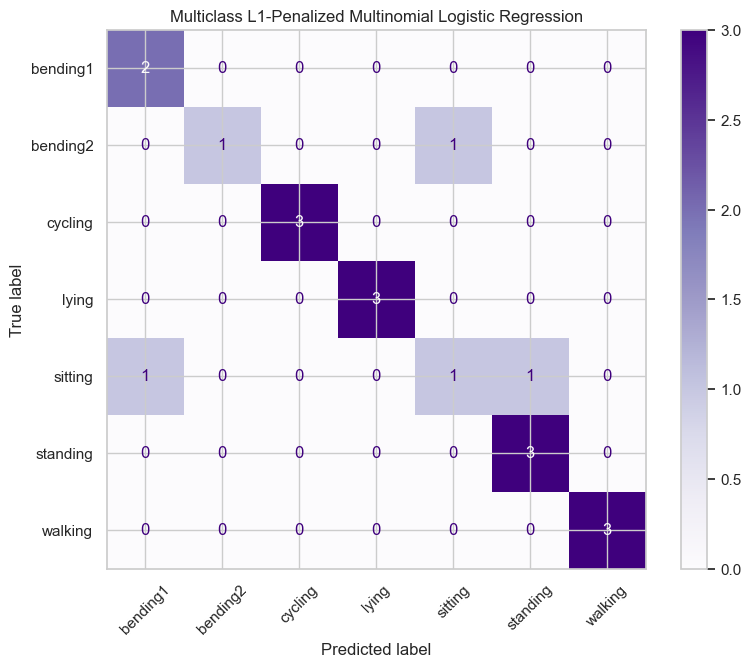

In [36]:
# Fit final multinomial model and evaluate on test set

best_multi_l = int(multi_cv_results.iloc[0]["l"])
best_mc_C = float(multi_cv_results.iloc[0]["best_C"])

best_mc_table = make_segment_features(manifest, l=best_multi_l)

train_mc = best_mc_table[best_mc_table["split"] == "train"].reset_index(drop=True).copy()
test_mc = best_mc_table[best_mc_table["split"] == "test"].reset_index(drop=True).copy()

featurecols_mc = [c for c in best_mc_table.columns if c not in ["activity", "dataset", "split", "binary_y"]]

X_train_mc = train_mc[featurecols_mc]
y_train_mc = train_mc["activity"]
X_test_mc = test_mc[featurecols_mc]
y_test_mc = test_mc["activity"]

mc_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression(
        penalty="l1",
        solver="saga",
        multi_class="multinomial",
        C=best_mc_C,
        max_iter=10000,
        tol=1e-4,
        random_state=RANDOM_STATE
    ))
])

mc_pipe.fit(X_train_mc, y_train_mc)
mc_test_pred = mc_pipe.predict(X_test_mc)

mc_test_accuracy = accuracy_score(y_test_mc, mc_test_pred)
mc_test_error = 1 - mc_test_accuracy

print("Multiclass test accuracy:", round(mc_test_accuracy, 4))
print("Multiclass test error:", round(mc_test_error, 4))

labels_sorted = sorted(y_train_mc.unique())
cm_mc = confusion_matrix(y_test_mc, mc_test_pred, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mc, display_labels=labels_sorted)
disp.plot(ax=ax, cmap="Purples", xticks_rotation=45)
plt.title("Multiclass L1-Penalized Multinomial Logistic Regression")
plt.show()



The multinomial model has test accuracy 0.8421, corresponding to 3 errors among 19 observations. I also examine one-vs-rest ROC curves, treating each activity as the positive class in turn.

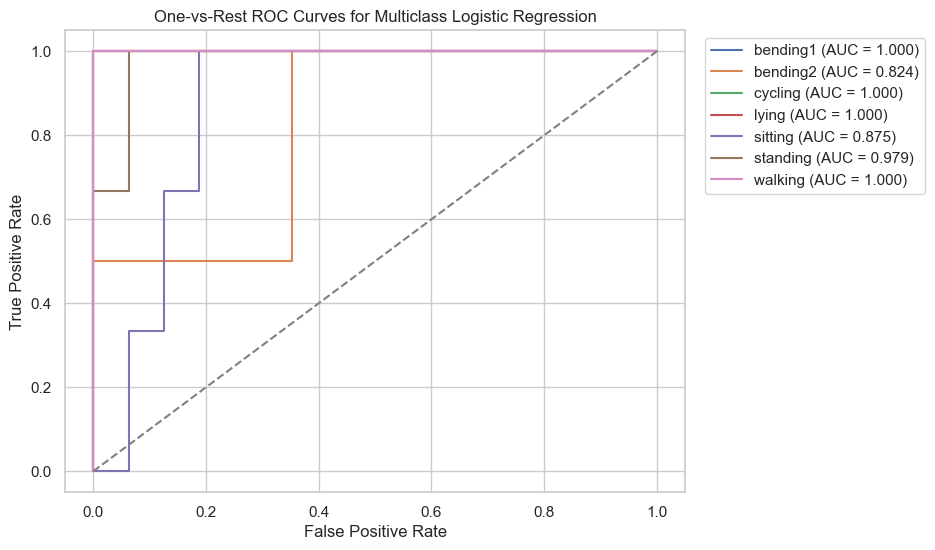

In [37]:
## one-vs-rest multiclass ROC curves

mc_test_probs = mc_pipe.predict_proba(X_test_mc)
class_order = mc_pipe.named_steps["logit"].classes_

y_test_binarized = label_binarize(y_test_mc, classes=class_order)

plt.figure(figsize=(8, 6))
for i, cls in enumerate(class_order):
    fpr, tpr, _ = roc_curve(y_test_binarized[:, i], mc_test_probs[:, i])
    auc_val = roc_auc_score(y_test_binarized[:, i], mc_test_probs[:, i])
    plt.plot(fpr, tpr, label=f"{cls} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves for Multiclass Logistic Regression")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


The one-vs-rest curves summarize discrimination separately for each activity.

#### Gaussian and Multinomial Naive Bayes

I select $l$ and the model hyperparameter independently for Gaussian NB and Multinomial NB using the training data.

In [38]:

nb_cv = multiclass_cv
gaussian_rows = []
multinomial_rows = []

for l in range(1, 21):
    table_l = make_segment_features(manifest, l=l)
    train_l = table_l[table_l["split"] == "train"].reset_index(drop=True)
    cols_l = [
        c for c in table_l.columns
        if c not in ["activity", "dataset", "split", "binary_y"]
    ]
    X_l = train_l[cols_l]
    y_l = train_l["activity"]

    gaussian_grid = GridSearchCV(
        GaussianNB(),
        {"var_smoothing": np.logspace(-12, -6, 13)},
        cv=nb_cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    gaussian_grid.fit(X_l, y_l)
    gaussian_rows.append({
        "l": l,
        "var_smoothing": gaussian_grid.best_params_["var_smoothing"],
        "best_cv_accuracy": gaussian_grid.best_score_,
    })

    # Scaling is fitted inside each fold and produces nonnegative inputs without
    # consulting the test set.
    multinomial_pipe = Pipeline([
        ("scale", MinMaxScaler()),
        ("nb", MultinomialNB()),
    ])
    multinomial_grid = GridSearchCV(
        multinomial_pipe,
        {"nb__alpha": np.logspace(-3, 2, 12)},
        cv=nb_cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    multinomial_grid.fit(X_l, y_l)
    multinomial_rows.append({
        "l": l,
        "alpha": multinomial_grid.best_params_["nb__alpha"],
        "best_cv_accuracy": multinomial_grid.best_score_,
    })

gaussian_results = pd.DataFrame(gaussian_rows).sort_values(
    ["best_cv_accuracy", "l"], ascending=[False, True]
).reset_index(drop=True)
multinomial_results = pd.DataFrame(multinomial_rows).sort_values(
    ["best_cv_accuracy", "l"], ascending=[False, True]
).reset_index(drop=True)

print("Best Gaussian NB candidates")
display(gaussian_results.head())
print("Best Multinomial NB candidates")
display(multinomial_results.head())


Best Gaussian NB candidates


,l,var_smoothing,best_cv_accuracy
0,1,1.000000e-08,0.884804
1,2,1.000000e-12,0.856209
2,3,1.000000e-07,0.782680
3,5,1.000000e-06,0.754902
4,17,1.000000e-06,0.754902


Best Multinomial NB candidates


,l,alpha,best_cv_accuracy
0,15,0.008111,0.841503
1,10,0.065793,0.839869
2,1,0.008111,0.826797
3,2,0.002848,0.826797
4,17,0.001000,0.826797


In [39]:
# Fit each NB model using its own cross-validated segmentation and hyperparameter.
best_gaussian_l = int(gaussian_results.iloc[0]["l"])
best_gnb_smoothing = float(gaussian_results.iloc[0]["var_smoothing"])
gnb_table = make_segment_features(manifest, best_gaussian_l)
gnb_train = gnb_table[gnb_table["split"] == "train"]
gnb_test = gnb_table[gnb_table["split"] == "test"]
gnb_cols = [
    c for c in gnb_table.columns
    if c not in ["activity", "dataset", "split", "binary_y"]
]
gnb = GaussianNB(var_smoothing=best_gnb_smoothing)
gnb.fit(gnb_train[gnb_cols], gnb_train["activity"])
gnb_pred = gnb.predict(gnb_test[gnb_cols])
gnb_acc = accuracy_score(gnb_test["activity"], gnb_pred)

best_multinomial_l = int(multinomial_results.iloc[0]["l"])
best_mnb_alpha = float(multinomial_results.iloc[0]["alpha"])
mnb_table = make_segment_features(manifest, best_multinomial_l)
mnb_train = mnb_table[mnb_table["split"] == "train"]
mnb_test = mnb_table[mnb_table["split"] == "test"]
mnb_cols = [
    c for c in mnb_table.columns
    if c not in ["activity", "dataset", "split", "binary_y"]
]
mnb = Pipeline([
    ("scale", MinMaxScaler()),
    ("nb", MultinomialNB(alpha=best_mnb_alpha)),
])
mnb.fit(mnb_train[mnb_cols], mnb_train["activity"])
mnb_pred = mnb.predict(mnb_test[mnb_cols])
mnb_acc = accuracy_score(mnb_test["activity"], mnb_pred)

print(
    "Gaussian NB: l =", best_gaussian_l,
    ", CV accuracy =", round(gaussian_results.iloc[0]["best_cv_accuracy"], 4),
    ", test accuracy =", round(gnb_acc, 4),
    ", test error =", round(1 - gnb_acc, 4),
)
print(
    "Multinomial NB: l =", best_multinomial_l,
    ", CV accuracy =", round(multinomial_results.iloc[0]["best_cv_accuracy"], 4),
    ", test accuracy =", round(mnb_acc, 4),
    ", test error =", round(1 - mnb_acc, 4),
)


Gaussian NB: l = 1 , CV accuracy = 0.8848 , test accuracy = 0.8947 , test error = 0.1053
Multinomial NB: l = 15 , CV accuracy = 0.8415 , test accuracy = 0.8421 , test error = 0.1579


In [40]:
comparison = pd.DataFrame({
    "Model": [
        "Multinomial Logistic Regression (L1)",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes",
    ],
    "Selected l": [best_multi_l, best_gaussian_l, best_multinomial_l],
    "CV Accuracy": [
        multi_cv_results.iloc[0]["best_cv_accuracy"],
        gaussian_results.iloc[0]["best_cv_accuracy"],
        multinomial_results.iloc[0]["best_cv_accuracy"],
    ],
    "Test Accuracy": [mc_test_accuracy, gnb_acc, mnb_acc],
    "Test Error": [1 - mc_test_accuracy, 1 - gnb_acc, 1 - mnb_acc],
})

comparison.sort_values("Test Accuracy", ascending=False)


,Model,Selected l,CV Accuracy,Test Accuracy,Test Error
1,Gaussian Naive Bayes,1,0.884804,0.894737,0.105263
0,Multinomial Logistic Regression (L1),2,0.914216,0.842105,0.157895
2,Multinomial Naive Bayes,15,0.841503,0.842105,0.157895


Gaussian NB made 2 test errors, while L1 multinomial logistic regression and Multinomial NB each made 3. Gaussian NB made one fewer test error, but the test set has only 19 observations, so this difference is not enough to claim it is clearly better.

## 3. ISLR 4.8.3

For QDA with one predictor, the Bayes classifier assigns an observation $X=x$ to the class with the largest posterior probability:

$$
P(Y=k \mid X=x) \propto \pi_k f_k(x),
$$

where $\pi_k$ is the prior probability for class $k$, and

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking the log and dropping the constant term $-\frac{1}{2}\log(2\pi)$ gives the discriminant function:

$$
\delta_k(x)
=
\log(\pi_k)
-\frac{1}{2}\log(\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term:

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
+
\log(\pi_k)
-
\frac{1}{2}\log(\sigma_k^2).
$$

To find the boundary between classes $k$ and $j$, set $\delta_k(x)=\delta_j(x)$. This gives a quadratic equation in $x$:

$$
\left(
\frac{1}{2\sigma_j^2}
-
\frac{1}{2\sigma_k^2}
\right)x^2
+
\left(
\frac{\mu_k}{\sigma_k^2}
-
\frac{\mu_j}{\sigma_j^2}
\right)x
+
C
=
0,
$$

where $C$ collects the remaining constant terms.

Since the coefficient of $x^2$ is generally nonzero when the class variances differ, the classifier is not linear. It is quadratic.

In LDA, all classes have the same variance, so the $x^2$ terms cancel out. In QDA, the class-specific variances are allowed to differ, so the quadratic term remains.

## 4. ISLR 4.8.7



Let $Y=\text{Yes}$ mean that a company issues a dividend, and let $Y=\text{No}$ mean that it does not issue a dividend.

We are given:

$$
P(Y=\text{Yes})=0.8
$$

and

$$
P(Y=\text{No})=0.2.
$$

The conditional distributions are:

$$
X \mid Y=\text{Yes} \sim N(10, 36)
$$

and

$$
X \mid Y=\text{No} \sim N(0, 36).
$$

We want to calculate:

$$
P(Y=\text{Yes} \mid X=4).
$$

Using Bayes' theorem:

$$
P(Y=\text{Yes} \mid X=4)
=
\frac{P(Y=\text{Yes})f_{\text{Yes}}(4)}
{P(Y=\text{Yes})f_{\text{Yes}}(4)
+
P(Y=\text{No})f_{\text{No}}(4)}.
$$

Because both normal distributions have the same variance, the common normalizing constant cancels.

For companies that issued dividends:

$$
f_{\text{Yes}}(4)
\propto
\exp\left(
-\frac{(4-10)^2}{2(36)}
\right)
=
\exp\left(-\frac{36}{72}\right)
=
e^{-0.5}.
$$

For companies that did not issue dividends:

$$
f_{\text{No}}(4)
\propto
\exp\left(
-\frac{(4-0)^2}{2(36)}
\right)
=
\exp\left(-\frac{16}{72}\right)
=
e^{-2/9}.
$$

Substituting into Bayes' theorem:

$$
P(Y=\text{Yes} \mid X=4)
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-2/9}}.
$$

Therefore:

$$
P(Y=\text{Yes} \mid X=4)
\approx 0.757.
$$

So, the probability that the company will issue a dividend is approximately **75.7%**.

Although a 4% profit is closer to the mean profit of companies that did not issue dividends, the prior probability of issuing a dividend is high at 80%. This makes issuing a dividend more likely overall.
